# 03 · Skew: higher averages or a broader shift?
**Insight:** ranks limit how much the *size* of a few extreme purchases can dominate a comparison. They help describe whether B tends to outrank A. Means describe average dollars, including the large purchases. Neither is the uniquely “true” difference.

We compare **two ways to raise population mean spending by exactly 40%**: multiply everybody’s spending distribution by 1.4, or multiply spending by 9 for a randomly selected 5% of B. Same mean lift, different distributional stories. All data are simulated independent purchases, not observed customers or causal evidence.

**Tests:** Welch’s tests equality of population means. Mann–Whitney’s standard null is identical distributions; its U statistic estimates P(B > A) + ½P(B = A). A higher U indicates a tendency to outrank, not that every quantile is higher. The standard test is not generally a test of equal medians, nor a generally calibrated test of P(B > A) = ½ under arbitrary different shapes. Both tests are two-sided at 5%.

In [1]:
from pathlib import Path
import json, platform
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 20261127
REPETITIONS = 20_000
N = 100  # independent customers per group
ALPHA = .05
MEDIAN = 30
SIGMA = 1
BROAD_FACTOR = 1.4
TAIL_PROB = .05
TAIL_FACTOR = 9
OUT = Path("outputs/03-skew-means-and-ranks")
OUT.mkdir(parents=True, exist_ok=True)
names = ["Identical distributions", "Broad shift", "Rare big spenders"]
mean_a = MEDIAN*np.exp(SIGMA**2/2)
rank_broad = stats.norm.cdf(np.log(BROAD_FACTOR)/(np.sqrt(2)*SIGMA))
rank_tail = (1-TAIL_PROB)*.5 + TAIL_PROB*stats.norm.cdf(np.log(TAIL_FACTOR)/(np.sqrt(2)*SIGMA))
truth = pd.DataFrame(dict(scenario=names, mean_a=mean_a,
    mean_b=[mean_a, mean_a*BROAD_FACTOR, mean_a*(1+TAIL_PROB*(TAIL_FACTOR-1))],
    probability_b_beats_a=[.5, rank_broad, rank_tail]))
truth["mean_lift_pct"] = 100*(truth.mean_b/truth.mean_a-1)
truth.to_csv(OUT / "population_truth.csv", index=False)
display(truth.round(3))

,scenario,mean_a,mean_b,probability_b_beats_a,mean_lift_pct
0,Identical distributions,49.462,49.462,0.500,0.0
1,Broad shift,49.462,69.246,0.594,40.0
2,Rare big spenders,49.462,69.246,0.522,40.0


## 1 · Same average lift, different stories
A follows a lognormal distribution (median $30, log-scale SD 1). In the broad-shift case, B is 1.4 times an independent draw from A’s distribution. In the rare-spender case, B is unchanged with probability 95%, and multiplied by 9 with probability 5%, independently of the original spend.

Both B means equal 1.4 × A’s mean because 0.95 + 0.05 × 9 = 1.4. But their rank effects differ. For independent lognormal draws, P(kX > Y) = Φ(log(k)/(√2σ)); the mixture probability is the weighted average of that expression and ½. Population values below are analytic, not estimated from a hand-picked sample.

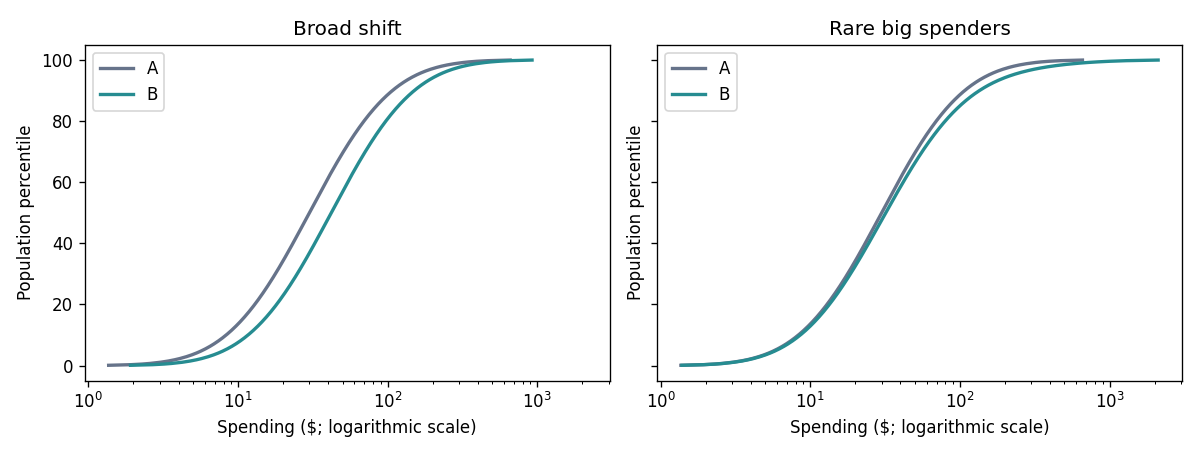

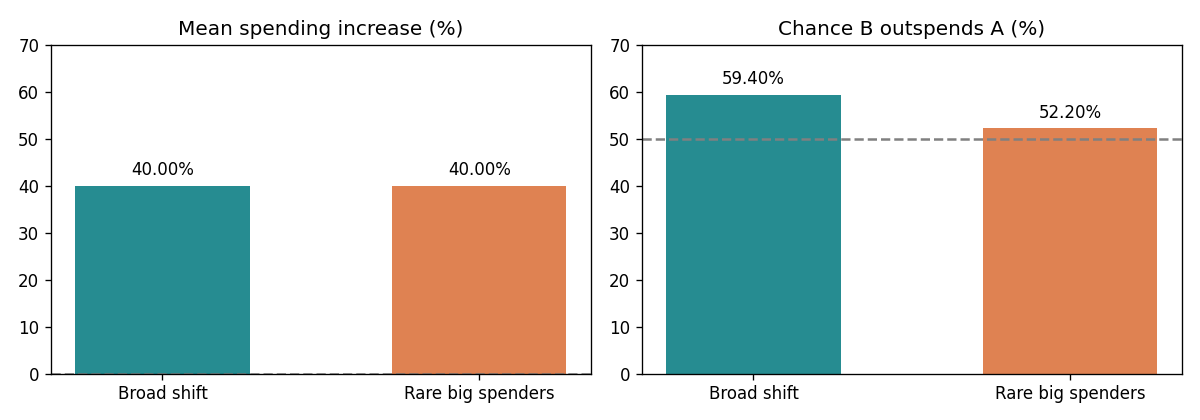

In [2]:
# Exact population quantile curves; log x-axis keeps the long tail visible.
quantiles = np.linspace(.001, .999, 500)
q_a = stats.lognorm.ppf(quantiles, s=SIGMA, scale=MEDIAN)
x_grid = np.geomspace(.01, 100_000, 30_000)
cdf_mix = ((1-TAIL_PROB)*stats.lognorm.cdf(x_grid, s=SIGMA, scale=MEDIAN)
           + TAIL_PROB*stats.lognorm.cdf(x_grid, s=SIGMA, scale=MEDIAN*TAIL_FACTOR))
q_tail = np.interp(quantiles, cdf_mix, x_grid)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True, sharey=True)
for ax, title, q_b in zip(axes, names[1:], [BROAD_FACTOR*q_a, q_tail]):
    ax.plot(q_a, 100*quantiles, label="A", color="#66738a", linewidth=2)
    ax.plot(q_b, 100*quantiles, label="B", color="#268c91", linewidth=2)
    ax.set_xscale("log")
    ax.set(title=title, xlabel="Spending ($; logarithmic scale)", ylabel="Population percentile")
    ax.legend()
fig.tight_layout()
fig.savefig(OUT / "population_distributions.png", dpi=160)
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sub = truth.iloc[1:]
for ax, values, title, reference in [
    (axes[0], sub.mean_lift_pct, "Mean spending increase (%)", 0),
    (axes[1], 100*sub.probability_b_beats_a, "Chance B outspends A (%)", 50)]:
    bars = ax.bar(names[1:], values, color=["#268c91", "#df8252"], width=.55)
    ax.bar_label(bars, labels=[f"{v:.2f}%" for v in values], padding=4)
    ax.axhline(reference, color="gray", linestyle="--")
    ax.set(title=title, ylim=(0, 70))
fig.tight_layout()
fig.savefig(OUT / "same_mean_different_rank_effect.png", dpi=160)
plt.show()

## 2 · Repeat both tests on the same samples
Draw 100 independent observations per group, 20,000 times. Include identical distributions as a null check. Record rejection rates with 95% Wilson Monte Carlo intervals, mean differences and rank effects. Use Mann–Whitney’s asymptotic method with continuity correction; data are continuous with no expected ties.

**Interpret rejection rates carefully:** the alternative scenarios differ in both means and rank tendency. Neither test’s rejection there is a false positive. This is not a contest between tests of an identical scientific question. A nonsignificant result does not prove no difference. Welch’s finite-sample approximation can be imperfect under strong skew; Mann–Whitney requires independent rankable observations, but not normality.

In [3]:
rng = np.random.default_rng(SEED)
a = rng.lognormal(np.log(MEDIAN), SIGMA, (REPETITIONS, N))
base_b = rng.lognormal(np.log(MEDIAN), SIGMA, (REPETITIONS, N))
tail_mask = rng.random((REPETITIONS, N)) < TAIL_PROB
rows, trials, effects = [], [], []
for name in names:
    b = (base_b if name == names[0] else
         base_b*BROAD_FACTOR if name == names[1] else
         base_b*np.where(tail_mask, TAIL_FACTOR, 1))
    welch = stats.ttest_ind(b, a, axis=1, equal_var=False)
    mw = stats.mannwhitneyu(b, a, axis=1, alternative="two-sided", method="asymptotic", use_continuity=True)
    rank_effect = mw.statistic/(N*N)
    difference = b.mean(axis=1)-a.mean(axis=1)
    effects.append(dict(scenario=name, average_sample_mean_difference=difference.mean(),
                        average_sample_probability_b_beats_a=rank_effect.mean()))
    for test, result in [("Welch (means)", welch), ("Mann–Whitney (ranks)", mw)]:
        rejected = result.pvalue < ALPHA
        count = int(rejected.sum())
        interval = stats.binomtest(count, REPETITIONS).proportion_ci(method="wilson")
        rows.append(dict(scenario=name, test=test, repetitions=REPETITIONS, rejections=count,
            rejection_pct=100*rejected.mean(), mc_low_pct=100*interval.low, mc_high_pct=100*interval.high))
        trials.append(pd.DataFrame(dict(scenario=name, test=test, repetition=np.arange(REPETITIONS),
            p_value=result.pvalue, mean_difference=difference, probability_b_beats_a=rank_effect)))
summary = pd.DataFrame(rows)
summary.to_csv(OUT / "metrics.csv", index=False)
pd.DataFrame(effects).to_csv(OUT / "estimated_effects.csv", index=False)
pd.concat(trials, ignore_index=True).to_csv(OUT / "trials.csv", index=False)
display(summary.round(3))
display(pd.DataFrame(effects).round(3))
# Verify U's orientation against direct pairwise comparisons for one sample.
assert np.isclose(rank_effect[0], (b[0,:,None] > a[0,None,:]).mean())
assert np.isclose(truth.iloc[1].mean_b, truth.iloc[2].mean_b)
assert np.isfinite(summary.select_dtypes("number")).all().all()
assert ((rank_effect >= 0) & (rank_effect <= 1)).all()

,scenario,test,repetitions,rejections,rejection_pct,mc_low_pct,mc_high_pct
0,Identical distributions,Welch (means),20000,862,4.310,4.037,4.600
1,Identical distributions,Mann–Whitney (ranks),20000,1014,5.070,4.774,5.383
2,Broad shift,Welch (means),20000,9403,47.015,46.324,47.707
3,Broad shift,Mann–Whitney (ranks),20000,12763,63.815,63.146,64.478
4,Rare big spenders,Welch (means),20000,3146,15.730,15.232,16.241
5,Rare big spenders,Mann–Whitney (ranks),20000,1662,8.310,7.935,8.701


,scenario,average_sample_mean_difference,average_sample_probability_b_beats_a
0,Identical distributions,-0.053,0.500
1,Broad shift,19.715,0.594
2,Rare big spenders,19.883,0.522


## 3 · What each test detects
The null scenario checks false alarms; the other bars show sensitivity to different alternatives. The 5% line is a false-alarm reference only for the null. Shared draws across scenarios reduce comparison noise, so these scenario estimates are correlated.

Out[1]: 348


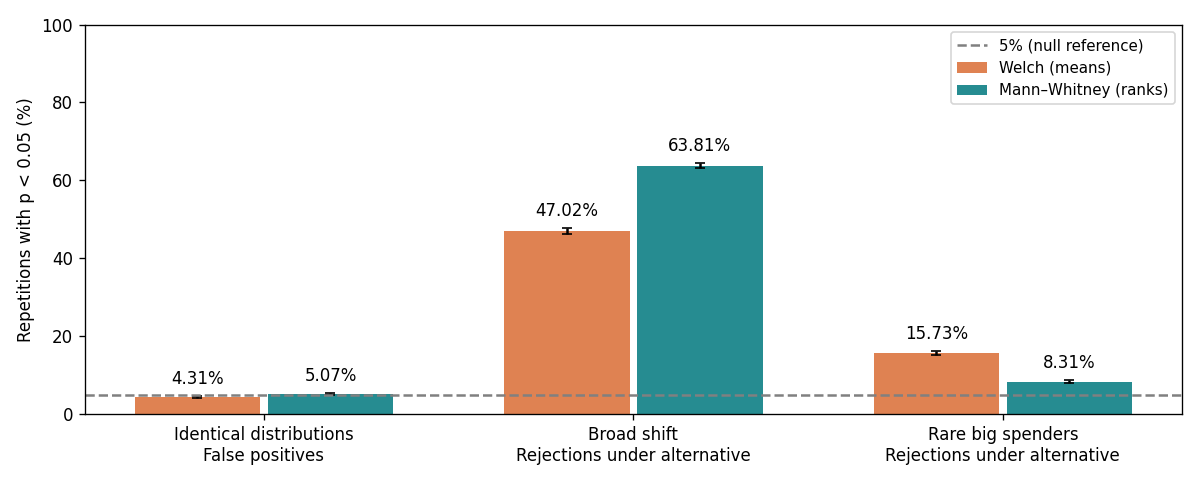

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(3)
for test, offset, color in [("Welch (means)", -.18, "#df8252"), ("Mann–Whitney (ranks)", .18, "#268c91")]:
    sub = summary[summary.test == test]
    y = sub.rejection_pct.to_numpy()
    err = np.maximum(0, np.vstack([y-sub.mc_low_pct.to_numpy(), sub.mc_high_pct.to_numpy()-y]))
    bars = ax.bar(x+offset, y, .34, label=test, color=color, yerr=err, capsize=3)
    ax.bar_label(bars, labels=[f"{v:.2f}%" for v in y], padding=5)
ax.axhline(5, linestyle="--", color="gray", label="5% (null reference)")
ax.set_xticks(x, ["Identical distributions\nFalse positives", "Broad shift\nRejections under alternative", "Rare big spenders\nRejections under alternative"])
ax.set(ylabel="Repetitions with p < 0.05 (%)", ylim=(0, 100))
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(OUT / "test_rejection_rates.png", dpi=180)
plt.show()
settings = dict(seed=SEED, repetitions=REPETITIONS, n_per_group=N, alpha=ALPHA,
    median=MEDIAN, log_sd=SIGMA, broad_factor=BROAD_FACTOR, tail_probability=TAIL_PROB,
    tail_factor=TAIL_FACTOR, shared_draws_across_scenarios=True,
    mw_method="asymptotic with continuity correction", python=platform.python_version(),
    numpy=np.__version__, scipy=scipy.__version__)
(OUT / "settings.json").write_text(json.dumps(settings, indent=2))

### Results from this run
With 100 observations per group, the broad-shift rejection rates were **47.015% for Welch’s** and **63.815% for Mann–Whitney**. For rare big spenders they were **15.730%** and **8.310%**, respectively. Rare high purchases also increase sample-to-sample uncertainty, so even Welch’s often misses the genuine mean increase at this sample size.

Under identical distributions, false-positive rates were **4.310% for Welch’s** and **5.070% for Mann–Whitney**. Welch’s is somewhat conservative in this finite-sample skewed setup; do not describe both null rates as exactly calibrated. These numbers are the saved run, not universal performance guarantees; refresh this summary if changing settings.


## Takeaway · Ranks uncover a different aspect of change
**Both alternatives raise average spending by 40%.** Yet B’s chance of outspending A is about **59.4% for the broad shift**, compared with **52.2% for rare big spenders**. The rare buyers have a large dollar impact, but affect only a small fraction of pairwise rankings.

Once a purchase exceeds another, making it even larger does not change that pair’s ordering. It can still move past other values and change additional ranks—rank methods are not immune to unusual observations.

Use the mean to discuss **average dollars**. Use the rank effect to discuss **the tendency for one random observation to exceed another**. Neither establishes that a majority of individual people improved: these are independent groups, not matched changes. A higher rank effect alone does not prove a broad shift; the distribution plots and known simulation design establish that here.

A low Mann–Whitney rejection rate for rare spenders does not mean the revenue lift is unreal; a higher rejection rate in the broad scenario does not make it universally better. Legitimate large purchases should not be discarded simply because they are extreme.

**Review prompt:** How can the same 40% mean lift produce such different probabilities that B outspends A?

## Website presentation brief
**Lead insight:** “The same average lift can hide very different customer behaviour.”

1. Show **+40% mean spending in both scenarios** first, using saved population values.
2. Reveal the population distributions on matching axes. Clearly label the logarithmic spending scale; it compresses dollar distances but preserves ordering. Explain the broad multiplier versus the random 5% high-spending component.
3. Show the rank-effect cards: roughly **59.4% versus 52.2% chance B outspends A**, with 50% as the no-tendency reference. This is the central reveal—not which test wins.
4. Show the simulation rejection chart as supporting evidence. Label the null and alternatives separately; explain that the tests answer different questions. Read all metrics from saved outputs.
5. Close: “Means describe average dollars. Ranks describe who tends to be larger. Choose the question before the test.”

Keep assumptions, exact U interpretation, Monte Carlo intervals and simulation settings available as optional detail. Do not call Mann–Whitney a universal median test or claim skew automatically invalidates Welch’s. No cherry-picked sample or claim that rare large purchases are errors. Website guidance only; no website changes included.
